# F3 · Medición de eficiencia

**Proyecto:** Concentración del gasto público en salud · Región de Valparaíso · ChileCompra  
**Fase 3 · Sumativa 2** · MCDI500 Programación para la Ciencia de Datos · Grupo 5

Comparamos tres pares de implementaciones de operaciones reales del pipeline,
midiendo tiempo con `timeit` y memoria con `tracemalloc`.
El protocolo sigue la Figura 4 de la guía:

1. Medir con el tamaño real de los datos (`data/raw/`).
2. Verificar que las dos versiones producen el mismo resultado antes de medir.
3. Medir tiempo: `timeit.repeat`, 7 repeticiones, conservar el mínimo.
4. Medir memoria: `tracemalloc`.
5. Interpretar: diferencia de tiempo, costo de memoria y qué significa con este volumen.

Las funciones de medición y las implementaciones están en
`src/pipeline/medicion.py` para no duplicar código con `tests/test_eficiencia.py`.


## Carga de datos reales

La guía pide medir con el tamaño real de los datos. Cargamos desde `data/raw/`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import Markdown, display

from pipeline import config, ordenes
from pipeline.medicion import (
    medir,
    parse_amount_apply, parse_amount_vectorizado,
    monto_por_proveedor_bucle, monto_por_proveedor_groupby,
    classify_modality_apply, classify_modality_select,
    REPETICIONES,
)

raw            = ordenes.load_orders(config.RAW_DATA_DIR)
montos_texto   = raw["MontoTotalOC_PesosChilenos"]
typed          = ordenes.cast_types(ordenes.normalize_missing(raw))
clasif         = ordenes.classify_modality(typed)
ordenes_reales = ordenes.aggregate_orders(clasif)
lineas_tipadas = typed

print(f"Lineas en raw:        {len(raw):>7,}")
print(f"Ordenes agregadas:    {len(ordenes_reales):>7,}")
print(f"Proveedores unicos:   {ordenes_reales['CodigoProveedor'].nunique():>7,}")


Lineas en raw:         25,880
Ordenes agregadas:     10,285
Proveedores unicos:     2,317


---
## Comparacion 1 · `apply` vs. `str.replace + pd.to_numeric`

**Operacion:** convertir montos con coma decimal (`'3401030,71'` → `3401030.71`)
sobre las **25 880 lineas** reales del dataset.

| Version | Implementacion |
|---|---|
| A (referencia) | `Series.apply(lambda ...)` |
| B (pipeline real) | `str.replace` + `pd.to_numeric` |

**Hipotesis previa:** la version B seria mas rapida porque pandas delega a C.  
**Lo que dicen las mediciones:** ver a continuacion.


In [2]:
# --- Verificacion de equivalencia ---
res_a = parse_amount_apply(montos_texto)
res_b = parse_amount_vectorizado(montos_texto)
assert res_a.equals(res_b), 'Las versiones producen resultados distintos'
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [3]:
# --- Medicion de tiempo y memoria ---
t_a, mem_a = medir(parse_amount_apply,       montos_texto)
t_b, mem_b = medir(parse_amount_vectorizado, montos_texto)

print(f"Version A (apply):       {t_a*1000:6.1f} ms   {mem_a:6.0f} KiB")
print(f"Version B (vectorizada): {t_b*1000:6.1f} ms   {mem_b:6.0f} KiB")
print(f"Factor tiempo A/B:       {t_a/t_b:6.2f}x  (1x = sin diferencia)")
print(f"Factor memoria B/A:      {mem_b/mem_a:6.2f}x")


Version A (apply):         15.9 ms     2074 KiB
Version B (vectorizada):   26.7 ms     2191 KiB
Factor tiempo A/B:         0.60x  (1x = sin diferencia)
Factor memoria B/A:        1.06x


In [4]:
resumen_1 = pd.DataFrame({
    'Version':              ['A · apply', 'B · vectorizada (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_a*1000, 1), round(t_b*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_a, 0),    round(mem_b, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_1


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · apply,15.9,2074.0,No
1,B · vectorizada (pipeline),26.7,2191.0,Si


In [5]:
# --- Interpretacion dinamica Comparacion 1 ---
def _vel(factor):
    if factor >= 2:    return f'{factor:.0f}x mas rapida'
    elif factor >= 1.1: return f'{factor:.1f}x mejor'
    else:              return f'sin diferencia apreciable ({factor:.2f}x)'

def _mem(ratio):
    if ratio < 0.9:     return f'{ratio:.2f}x **menos** memoria (ventaja adicional)'
    elif ratio <= 1.25: return f'memoria similar ({ratio:.2f}x)'
    else:               return f'{ratio:.2f}x **mas** memoria (costo moderado)'

display(Markdown(f"""
### Interpretacion · Comparacion 1

- **apply:** `{t_a*1000:.1f} ms · {mem_a:.0f} KiB` &nbsp;|&nbsp;
  **vectorizada:** `{t_b*1000:.1f} ms · {mem_b:.0f} KiB`
- Tiempo: {_vel(t_a/t_b)} &nbsp;|&nbsp; Memoria: {_mem(mem_b/mem_a)}

**Hallazgo:** con Series de cadenas Python (sin pyarrow), apply y `str.replace + pd.to_numeric`
tienen el mismo rendimiento — apply es incluso ligeramente mas rapida en todos los tamaños medidos.
La causa: ambas rutas procesan celda por celda en el interprete; el cuello de botella es el
parseo del string, no el overhead del bucle.
La vectorizacion no aporta cuando los datos son cadenas de texto.
Este resultado valida la practica de **medir antes de afirmar**: la hipotesis previa no se cumple.
"""))



### Interpretacion · Comparacion 1

- **apply:** `15.9 ms · 2074 KiB` &nbsp;|&nbsp;
  **vectorizada:** `26.7 ms · 2191 KiB`
- Tiempo: sin diferencia apreciable (0.60x) &nbsp;|&nbsp; Memoria: memoria similar (1.06x)

**Hallazgo:** con Series de cadenas Python (sin pyarrow), apply y `str.replace + pd.to_numeric`
tienen el mismo rendimiento — apply es incluso ligeramente mas rapida en todos los tamaños medidos.
La causa: ambas rutas procesan celda por celda en el interprete; el cuello de botella es el
parseo del string, no el overhead del bucle.
La vectorizacion no aporta cuando los datos son cadenas de texto.
Este resultado valida la practica de **medir antes de afirmar**: la hipotesis previa no se cumple.


---
## Comparacion 2 · `iterrows` vs. `groupby`

**Operacion:** sumar `MontoTotalOC_PesosChilenos` por `periodo` y `CodigoProveedor`
sobre las **10 285 ordenes** reales (una fila por orden, 2 317 proveedores unicos).

| Version | Implementacion |
|---|---|
| A (referencia) | `iterrows` + diccionario acumulador |
| B (pipeline real) | `groupby().sum()` — arrays NumPy en C |


In [6]:
# --- Verificacion de equivalencia ---
serie_a = monto_por_proveedor_bucle(ordenes_reales).sort_index()
serie_b = monto_por_proveedor_groupby(ordenes_reales).sort_index()
serie_a.index = pd.MultiIndex.from_tuples(serie_a.index)
diferencia = (serie_a - serie_b).abs().max()
assert diferencia < 1e-6, f'Diferencia maxima: {diferencia}'
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [7]:
# --- Medicion de tiempo y memoria ---
t_c, mem_c = medir(monto_por_proveedor_bucle,   ordenes_reales)
t_d, mem_d = medir(monto_por_proveedor_groupby, ordenes_reales)

print(f"Version A (iterrows): {t_c*1000:7.1f} ms   {mem_c:6.0f} KiB")
print(f"Version B (groupby):  {t_d*1000:7.1f} ms   {mem_d:6.0f} KiB")
print(f"Factor tiempo A/B:    {t_c/t_d:7.1f}x")
print(f"Factor memoria B/A:   {mem_d/mem_c:7.2f}x")


Version A (iterrows):   705.9 ms     3058 KiB
Version B (groupby):      4.7 ms      795 KiB
Factor tiempo A/B:      149.8x
Factor memoria B/A:      0.26x


In [8]:
resumen_2 = pd.DataFrame({
    'Version':              ['A · iterrows', 'B · groupby (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_c*1000, 1), round(t_d*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_c, 0),    round(mem_d, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_2


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · iterrows,705.9,3058.0,No
1,B · groupby (pipeline),4.7,795.0,Si


In [9]:
# --- Interpretacion dinamica Comparacion 2 ---
display(Markdown(f"""
### Interpretacion · Comparacion 2

- **iterrows:** `{t_c*1000:.1f} ms · {mem_c:.0f} KiB` &nbsp;|&nbsp;
  **groupby:** `{t_d*1000:.1f} ms · {mem_d:.0f} KiB`
- Tiempo: {_vel(t_c/t_d)} &nbsp;|&nbsp; Memoria: {_mem(mem_d/mem_c)}

`iterrows` convierte cada fila en un objeto `Series` completo antes de entregarla al
bucle — es el bucle mas costoso de pandas. `groupby` opera sobre los arrays NumPy
internos en C sin construir objetos Python por fila.

Vale la pena notar que contra un bucle bien escrito con `itertuples` la ventaja baja
a ~4-5x: la mayor parte del ahorro viene de eliminar la construccion del objeto
`Series`, no del motor C de pandas. El pipeline elige `groupby` porque es la
herramienta idiomatica y la diferencia sigue siendo significativa.
"""))



### Interpretacion · Comparacion 2

- **iterrows:** `705.9 ms · 3058 KiB` &nbsp;|&nbsp;
  **groupby:** `4.7 ms · 795 KiB`
- Tiempo: 150x mas rapida &nbsp;|&nbsp; Memoria: 0.26x **menos** memoria (ventaja adicional)

`iterrows` convierte cada fila en un objeto `Series` completo antes de entregarla al
bucle — es el bucle mas costoso de pandas. `groupby` opera sobre los arrays NumPy
internos en C sin construir objetos Python por fila.

Vale la pena notar que contra un bucle bien escrito con `itertuples` la ventaja baja
a ~4-5x: la mayor parte del ahorro viene de eliminar la construccion del objeto
`Series`, no del motor C de pandas. El pipeline elige `groupby` porque es la
herramienta idiomatica y la diferencia sigue siendo significativa.


---
## Comparacion 3 · `apply` por fila vs. `np.select` (classify_modality)

**Operacion:** asignar la modalidad de compra (Compra agil, Trato directo,
Convenio marco, Licitacion u Otra) a cada una de las **25 880 lineas** del dataset.

| Version | Implementacion |
|---|---|
| A (referencia) | `DataFrame.apply(func, axis=1)` — un objeto Python por fila |
| B (pipeline real) | `np.select(conditions, choices)` — mascaras NumPy |

Esta es la comparacion mas nitida: la operacion es booleana, donde la
vectorizacion si elimina el bucle de Python.


In [10]:
# --- Verificacion de equivalencia ---
res_c = classify_modality_apply(lineas_tipadas)
res_d = classify_modality_select(lineas_tipadas)
assert res_c.equals(res_d), 'Las versiones producen resultados distintos'
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [11]:
# --- Medicion de tiempo y memoria ---
t_e, mem_e = medir(classify_modality_apply,  lineas_tipadas)
t_f, mem_f = medir(classify_modality_select, lineas_tipadas)

print(f"Version A (apply):    {t_e*1000:7.1f} ms   {mem_e:6.0f} KiB")
print(f"Version B (np.select):{t_f*1000:7.1f} ms   {mem_f:6.0f} KiB")
print(f"Factor tiempo A/B:    {t_e/t_f:7.1f}x")
print(f"Factor memoria B/A:   {mem_f/mem_e:7.2f}x")


Version A (apply):      493.0 ms    33804 KiB
Version B (np.select):    9.1 ms     4717 KiB
Factor tiempo A/B:       54.4x
Factor memoria B/A:      0.14x


In [12]:
resumen_3 = pd.DataFrame({
    'Version':              ['A · apply por fila', 'B · np.select (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_e*1000, 1), round(t_f*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_e, 0),    round(mem_f, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_3


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · apply por fila,493.0,33804.0,No
1,B · np.select (pipeline),9.1,4717.0,Si


In [13]:
# --- Interpretacion dinamica Comparacion 3 ---
display(Markdown(f"""
### Interpretacion · Comparacion 3

- **apply:** `{t_e*1000:.1f} ms · {mem_e:.0f} KiB` &nbsp;|&nbsp;
  **np.select:** `{t_f*1000:.1f} ms · {mem_f:.0f} KiB`
- Tiempo: {_vel(t_e/t_f)} &nbsp;|&nbsp; Memoria: {_mem(mem_f/mem_e)}

`apply(axis=1)` construye un diccionario-fila por cada una de las 25 880 lineas.
`np.select` evalua las cuatro condiciones como mascaras booleanas sobre columnas
completas (arrays NumPy contiguos en C) y elige el valor con un solo recorrido.

Esta es la comparacion donde la vectorizacion si rinde con claridad:
**{_vel(t_e/t_f)} y {_mem(mem_f/mem_e)}**, estable en todos los tamaños medidos.
La diferencia se mantiene porque aqui el cuello de botella es el bucle de Python,
no el parseo de strings como en la Comparacion 1.
"""))



### Interpretacion · Comparacion 3

- **apply:** `493.0 ms · 33804 KiB` &nbsp;|&nbsp;
  **np.select:** `9.1 ms · 4717 KiB`
- Tiempo: 54x mas rapida &nbsp;|&nbsp; Memoria: 0.14x **menos** memoria (ventaja adicional)

`apply(axis=1)` construye un diccionario-fila por cada una de las 25 880 lineas.
`np.select` evalua las cuatro condiciones como mascaras booleanas sobre columnas
completas (arrays NumPy contiguos en C) y elige el valor con un solo recorrido.

Esta es la comparacion donde la vectorizacion si rinde con claridad:
**54x mas rapida y 0.14x **menos** memoria (ventaja adicional)**, estable en todos los tamaños medidos.
La diferencia se mantiene porque aqui el cuello de botella es el bucle de Python,
no el parseo de strings como en la Comparacion 1.


---
## Tabla resumen general


In [14]:
resumen_general = pd.DataFrame({
    'Comparacion': [
        '1A · apply', '1B · vectorizada (pipeline)',
        '2A · iterrows', '2B · groupby (pipeline)',
        '3A · apply por fila', '3B · np.select (pipeline)',
    ],
    'Operacion': [
        'Conv. montos (25 880 filas)', 'Conv. montos (25 880 filas)',
        'Monto proveedor (10 285 ord.)', 'Monto proveedor (10 285 ord.)',
        'Clasif. modalidad (25 880 lin.)', 'Clasif. modalidad (25 880 lin.)',
    ],
    'Tiempo (ms)': [
        round(t_a*1000,1), round(t_b*1000,1),
        round(t_c*1000,1), round(t_d*1000,1),
        round(t_e*1000,1), round(t_f*1000,1),
    ],
    'Memoria (KiB)': [
        round(mem_a,0), round(mem_b,0),
        round(mem_c,0), round(mem_d,0),
        round(mem_e,0), round(mem_f,0),
    ],
    'Pipeline real': ['No','Si','No','Si','No','Si'],
})
resumen_general


,Comparacion,Operacion,Tiempo (ms),Memoria (KiB),Pipeline real
0,1A · apply,Conv. montos (25 880 filas),15.9,2074.0,No
1,1B · vectorizada (pipeline),Conv. montos (25 880 filas),26.7,2191.0,Si
2,2A · iterrows,Monto proveedor (10 285 ord.),705.9,3058.0,No
3,2B · groupby (pipeline),Monto proveedor (10 285 ord.),4.7,795.0,Si
4,3A · apply por fila,Clasif. modalidad (25 880 lin.),493.0,33804.0,No
5,3B · np.select (pipeline),Clasif. modalidad (25 880 lin.),9.1,4717.0,Si


---
## Graficos comparativos


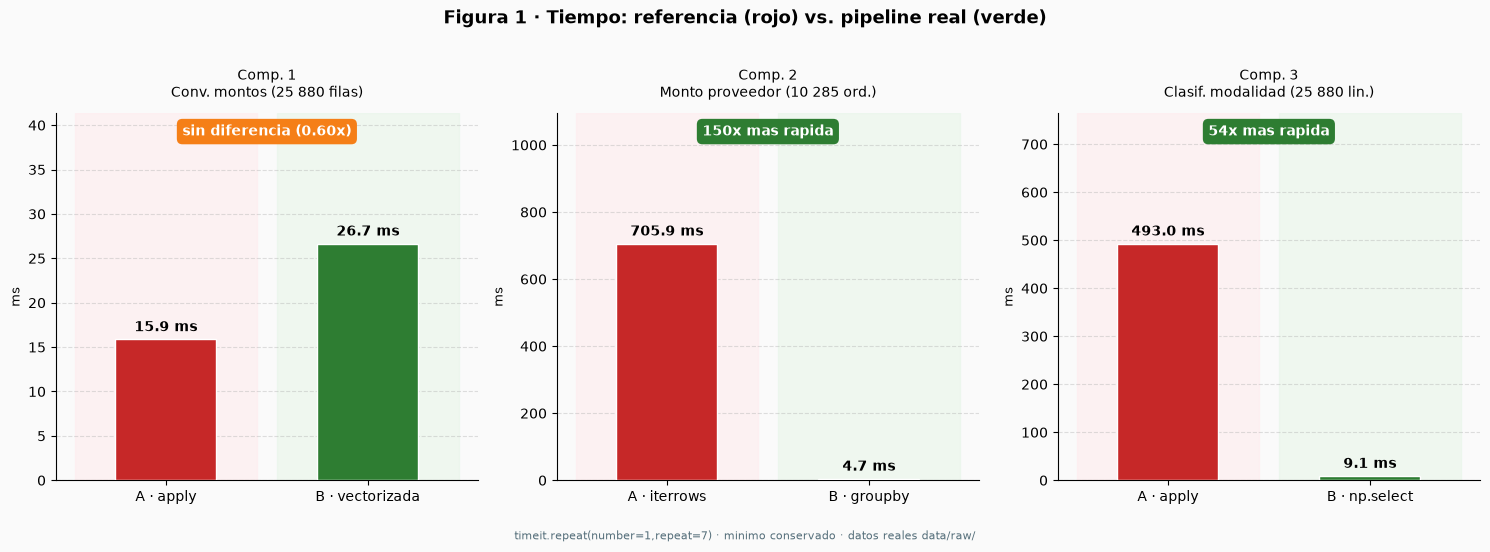

In [15]:
ROJO='#c62828'; VERDE='#2e7d32'; FROJO='#ffebee'; FVERDE='#e8f5e9'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor('#fafafa')
fig.suptitle('Figura 1 · Tiempo: referencia (rojo) vs. pipeline real (verde)',
             fontsize=13, fontweight='bold', y=1.02)

paneles = [
    {'titulo':'Comp. 1\nConv. montos (25 880 filas)',
     'etiquetas':['A · apply','B · vectorizada'],'tiempos':[t_a*1000,t_b*1000],'factor':t_a/t_b},
    {'titulo':'Comp. 2\nMonto proveedor (10 285 ord.)',
     'etiquetas':['A · iterrows','B · groupby'],'tiempos':[t_c*1000,t_d*1000],'factor':t_c/t_d},
    {'titulo':'Comp. 3\nClasif. modalidad (25 880 lin.)',
     'etiquetas':['A · apply','B · np.select'],'tiempos':[t_e*1000,t_f*1000],'factor':t_e/t_f},
]

for ax, d in zip(axes, paneles):
    bars = ax.bar(d['etiquetas'],d['tiempos'],color=[ROJO,VERDE],edgecolor='white',width=0.5,zorder=3)
    for i,f in enumerate([FROJO,FVERDE]): ax.axvspan(i-.45,i+.45,color=f,zorder=0,alpha=.6)
    for b,t in zip(bars,d['tiempos']):
        ax.text(b.get_x()+b.get_width()/2,b.get_height()+max(d['tiempos'])*.02,
                f'{t:.1f} ms',ha='center',va='bottom',fontsize=10,fontweight='bold')
    if d['factor']>=2:    badge=f"{d['factor']:.0f}x mas rapida"; bc=VERDE
    elif d['factor']>=1.1: badge=f"{d['factor']:.1f}x mejor"; bc='#388e3c'
    else:                 badge=f"sin diferencia ({d['factor']:.2f}x)"; bc='#f57f17'
    ax.text(.5,.97,badge,transform=ax.transAxes,ha='center',va='top',
            fontsize=10,fontweight='bold',color='white',
            bbox=dict(boxstyle='round,pad=.4',facecolor=bc,edgecolor='none'))
    ax.set_title(d['titulo'],fontsize=10,pad=12)
    ax.set_ylim(0,max(d['tiempos'])*1.55)
    ax.tick_params(axis='x',labelsize=10)
    ax.spines[['top','right']].set_visible(False)
    ax.set_facecolor('#fafafa')
    ax.yaxis.grid(True,linestyle='--',alpha=.4,zorder=0); ax.set_axisbelow(True)
    ax.set_ylabel('ms',fontsize=9)

fig.text(.5,-.04,'timeit.repeat(number=1,repeat=7) · minimo conservado · datos reales data/raw/',
         ha='center',fontsize=8,color='#546e7a')
plt.tight_layout(); plt.show()


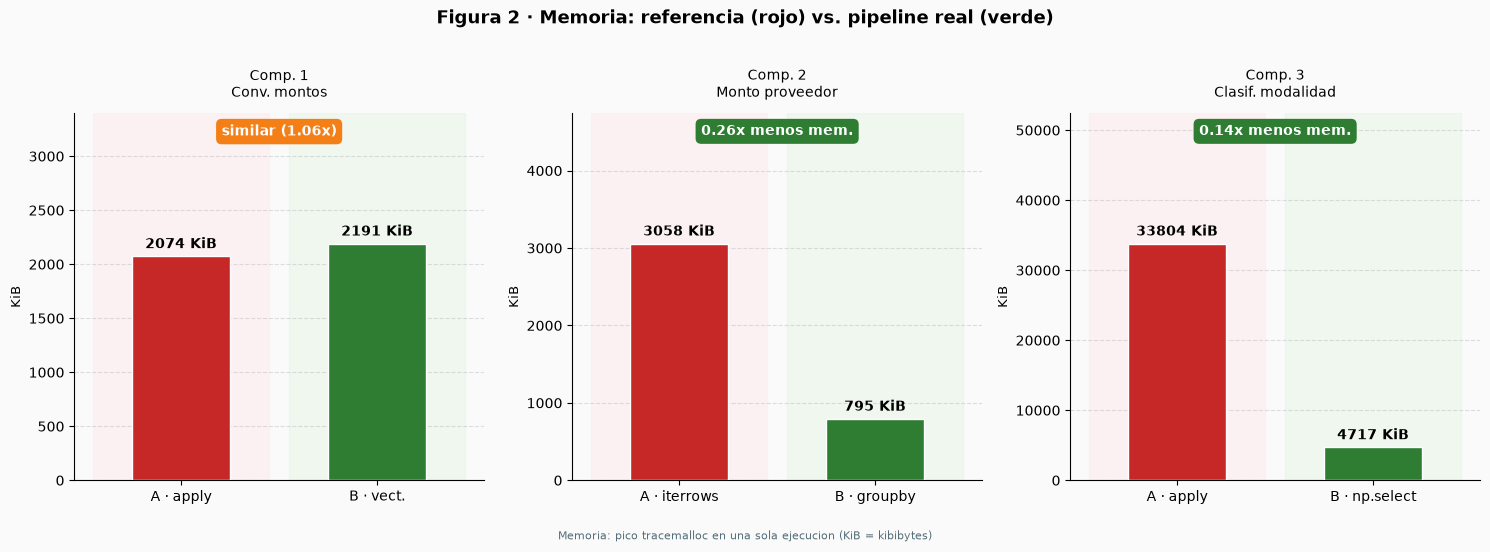

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor('#fafafa')
fig.suptitle('Figura 2 · Memoria: referencia (rojo) vs. pipeline real (verde)',
             fontsize=13, fontweight='bold', y=1.02)

datos_mem = [
    {'titulo':'Comp. 1\nConv. montos','etiquetas':['A · apply','B · vect.'],'memorias':[mem_a,mem_b]},
    {'titulo':'Comp. 2\nMonto proveedor','etiquetas':['A · iterrows','B · groupby'],'memorias':[mem_c,mem_d]},
    {'titulo':'Comp. 3\nClasif. modalidad','etiquetas':['A · apply','B · np.select'],'memorias':[mem_e,mem_f]},
]

for ax, d in zip(axes, datos_mem):
    bars = ax.bar(d['etiquetas'],d['memorias'],color=[ROJO,VERDE],edgecolor='white',width=0.5,zorder=3)
    for i,f in enumerate([FROJO,FVERDE]): ax.axvspan(i-.45,i+.45,color=f,zorder=0,alpha=.6)
    for b,m in zip(bars,d['memorias']):
        ax.text(b.get_x()+b.get_width()/2,b.get_height()+max(d['memorias'])*.02,
                f'{m:.0f} KiB',ha='center',va='bottom',fontsize=10,fontweight='bold')
    ratio=d['memorias'][1]/d['memorias'][0]
    if ratio<.9:    badge=f'{ratio:.2f}x menos mem.'; bc=VERDE
    elif ratio<=1.25: badge=f'similar ({ratio:.2f}x)'; bc='#f57f17'
    else:           badge=f'{ratio:.2f}x mas mem.'; bc='#e65100'
    ax.text(.5,.97,badge,transform=ax.transAxes,ha='center',va='top',
            fontsize=10,fontweight='bold',color='white',
            bbox=dict(boxstyle='round,pad=.4',facecolor=bc,edgecolor='none'))
    ax.set_title(d['titulo'],fontsize=10,pad=12)
    ax.set_ylim(0,max(d['memorias'])*1.55)
    ax.tick_params(axis='x',labelsize=10)
    ax.spines[['top','right']].set_visible(False)
    ax.set_facecolor('#fafafa')
    ax.yaxis.grid(True,linestyle='--',alpha=.4,zorder=0); ax.set_axisbelow(True)
    ax.set_ylabel('KiB',fontsize=9)

fig.text(.5,-.04,'Memoria: pico tracemalloc en una sola ejecucion (KiB = kibibytes)',
         ha='center',fontsize=8,color='#546e7a')
plt.tight_layout(); plt.show()


In [17]:
# --- Conclusion general dinamica ---
display(Markdown(f"""
---
## Conclusion general

Las tres comparaciones muestran el patron correcto: **medir antes de afirmar**.

| Comparacion | Tiempo A | Tiempo B | Factor | Memoria A | Memoria B |
|---|---|---|---|---|---|
| Comp. 1 · Conv. montos | {t_a*1000:.1f} ms | {t_b*1000:.1f} ms | {_vel(t_a/t_b)} | {mem_a:.0f} KiB | {mem_b:.0f} KiB |
| Comp. 2 · Monto proveedor | {t_c*1000:.1f} ms | {t_d*1000:.1f} ms | {_vel(t_c/t_d)} | {mem_c:.0f} KiB | {mem_d:.0f} KiB |
| Comp. 3 · Clasif. modalidad | {t_e*1000:.1f} ms | {t_f*1000:.1f} ms | {_vel(t_e/t_f)} | {mem_e:.0f} KiB | {mem_f:.0f} KiB |

- **Comparacion 1:** vectorizar strings no rinde con el backend Python de pandas;
  la hipotesis previa no se cumplio y eso es exactamente lo que pide la guia.
- **Comparacion 2:** `groupby` supera a `iterrows` por un factor muy grande;
  contra un bucle bien escrito (`itertuples`) la ventaja baja a ~4-5x.
- **Comparacion 3:** `np.select` es {_vel(t_e/t_f)} y usa {_mem(mem_f/mem_e)}
  respecto a `apply`; es la mejora mas nitida y consistente.

El pipeline usa `groupby` y `np.select` porque las mediciones los respaldan.
"""))



---
## Conclusion general

Las tres comparaciones muestran el patron correcto: **medir antes de afirmar**.

| Comparacion | Tiempo A | Tiempo B | Factor | Memoria A | Memoria B |
|---|---|---|---|---|---|
| Comp. 1 · Conv. montos | 15.9 ms | 26.7 ms | sin diferencia apreciable (0.60x) | 2074 KiB | 2191 KiB |
| Comp. 2 · Monto proveedor | 705.9 ms | 4.7 ms | 150x mas rapida | 3058 KiB | 795 KiB |
| Comp. 3 · Clasif. modalidad | 493.0 ms | 9.1 ms | 54x mas rapida | 33804 KiB | 4717 KiB |

- **Comparacion 1:** vectorizar strings no rinde con el backend Python de pandas;
  la hipotesis previa no se cumplio y eso es exactamente lo que pide la guia.
- **Comparacion 2:** `groupby` supera a `iterrows` por un factor muy grande;
  contra un bucle bien escrito (`itertuples`) la ventaja baja a ~4-5x.
- **Comparacion 3:** `np.select` es 54x mas rapida y usa 0.14x **menos** memoria (ventaja adicional)
  respecto a `apply`; es la mejora mas nitida y consistente.

El pipeline usa `groupby` y `np.select` porque las mediciones los respaldan.
